Fitted parameters: mu = 22.52550348408216, sigma = 18.69227549240202


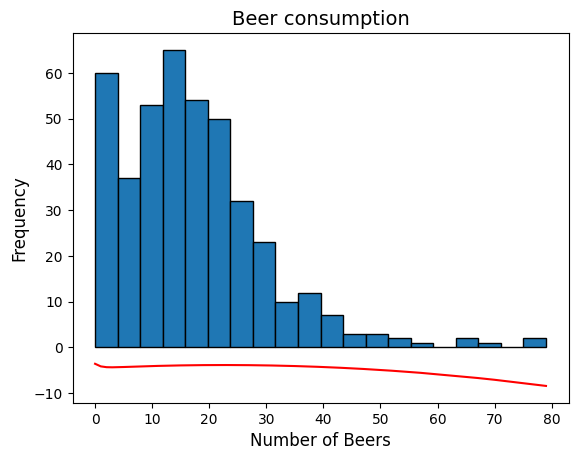

/var/folders/4b/vszk241x6rzfp13z0lgyr3pc0000gn/T/ipykernel_25073/1934569146.py:51: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


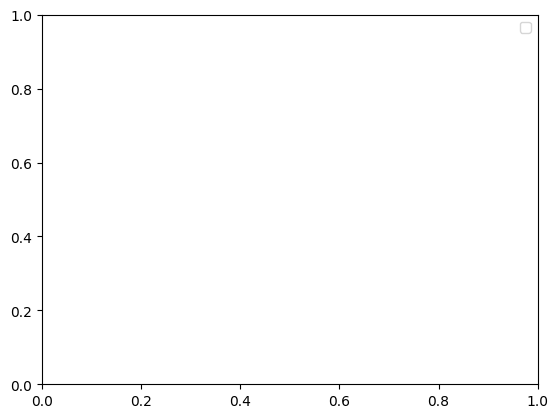

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as opt

streg1 = pd.read_csv('stregliste1.csv', delimiter=',', header=0, dtype=float)
beers1 = streg1[streg1.columns[0:5]].sum(axis=1)

streg2 = pd.read_csv('stregliste2.csv', delimiter=',', header=0, dtype=float)
beers2 = streg2[streg2.columns[0:5]].sum(axis=1)

streg3 = pd.read_csv('stregliste3.csv', delimiter=',', header=0, dtype=float)
beers3 = streg3[streg3.columns[0:5]].sum(axis=1)

streg4 = pd.read_csv('stregliste4.csv', delimiter=',', header=0, dtype=float)
beers4 = streg4[streg4.columns[0:5]].sum(axis=1)

beers_tot = np.concatenate((beers1, beers2, beers3, beers4))

bins = round(np.sqrt(len(beers_tot)))

plt.hist(beers_tot, bins=bins, edgecolor='black')
plt.xlabel('Number of Beers', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Beer consumption', fontsize=14)


hist, bin_edges = np.histogram(beers_tot, bins=bins)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

#var, cov = opt.curve_fit(
#    f,
#    bin_centers,
#    hist,
#    p0=[max(hist), np.mean(beers_tot), np.std(beers_tot)]
#)

mu = np.mean(beers_tot)
sigma = np.std(beers_tot)

def f(x, mu, sigma):
    return np.exp(-x) + np.log((1/(sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma) ** 2))

var, cov = opt.curve_fit(f, bin_centers, hist, p0=[mu, sigma])

print(f"Fitted parameters: mu = {var[0]}, sigma = {var[1]}")

plt.plot(np.sort(beers_tot), f(np.sort(beers_tot), *var), color='red', label='Fitted Curve')
plt.show()
plt.legend()



